# 01 · Toy Sparse Autoencoder

*SAE training / infrastructure workstream.*

`PROPOSAL.md` § 4.2 trains sparse autoencoders (SAEs) on residual-stream activations, using SAELens at
production scale. Here we hand-roll a **minimal** SAE from scratch, in plain PyTorch, so the mechanism
is fully visible before you ever touch SAELens's config surface. The real pipeline will use SAELens
directly; this is purely for building intuition.

An SAE learns to reconstruct an activation vector through a narrow, sparse bottleneck: encode into a
much *wider* (not narrower!) space than `d_model`, but force most of that wide space to be zero for any
given input. The bet (formalized by Elhage et al., 2022's superposition result, `PROPOSAL.md` § 2.1) is
that the handful of *active* dimensions correspond to interpretable features, even though no single
neuron in the original model did.


## Why superposition forces this

Why does an SAE encode into a *wider* space than `d_model`, instead of a narrower one like a normal
autoencoder? Because of **superposition** (Elhage et al., 2022, `PROPOSAL.md` § 2.1): a network can
represent *more* features than it has dimensions, by giving each feature its own direction and letting
those directions be non-orthogonal, i.e. not perfectly separated, as long as the features rarely activate
at the same time. When two features are sparse enough that they almost never co-occur, a little geometric
interference between their directions costs the model almost nothing.

This is a real phenomenon in real models, not a hypothetical: it's *why* individual neurons in GPT-2 are
polysemantic (each one participates in several unrelated "features"), and it's the formal reason we can't
just read features off the neurons directly and need dictionary learning at all.

Let's see it happen in the smallest possible model: 6 features, squeezed through 2 hidden dimensions
(so 2D vectors are easy to plot), reconstructed through a ReLU output. We'll train it twice, once where
the 6 features are **dense** (they show up together constantly, so overlapping directions would interfere
constantly) and once where they're **sparse** (they rarely co-occur, so overlap is cheap).


In [1]:
import torch
import torch.nn as nn

N_FEATURES, N_HIDDEN, BATCH, STEPS = 6, 2, 1024, 2000

class ToyModel(nn.Module):
    """x (n_features,) -> 2D hidden -> ReLU(W^T W x + b) reconstruction, same W both directions."""
    def __init__(self, n_features, n_hidden):
        super().__init__()
        self.W = nn.Parameter(torch.randn(n_hidden, n_features) * 0.5)
        self.b = nn.Parameter(torch.zeros(n_features))

    def forward(self, x):
        hidden = x @ self.W.T
        return torch.relu(hidden @ self.W + self.b)

def make_batch(batch, n_features, sparsity):
    # each feature present with prob (1 - sparsity); magnitude uniform(0, 1) when present
    present = (torch.rand(batch, n_features) > sparsity).float()
    return present * torch.rand(batch, n_features)

def train_toy_model(sparsity, steps=STEPS):
    model = ToyModel(N_FEATURES, N_HIDDEN)
    opt = torch.optim.Adam(model.parameters(), lr=1e-2)
    for _ in range(steps):
        x = make_batch(BATCH, N_FEATURES, sparsity)
        opt.zero_grad()
        loss = ((x - model(x)) ** 2).mean()
        loss.backward()
        opt.step()
    return model, loss.item()

dense_model, dense_loss = train_toy_model(sparsity=0.0)
sparse_model, sparse_loss = train_toy_model(sparsity=0.9)
print(f"dense  (sparsity=0.0) final reconstruction loss: {dense_loss:.4f}")
print(f"sparse (sparsity=0.9) final reconstruction loss: {sparse_loss:.4f}")


dense  (sparsity=0.0) final reconstruction loss: 0.0549
sparse (sparsity=0.9) final reconstruction loss: 0.0098


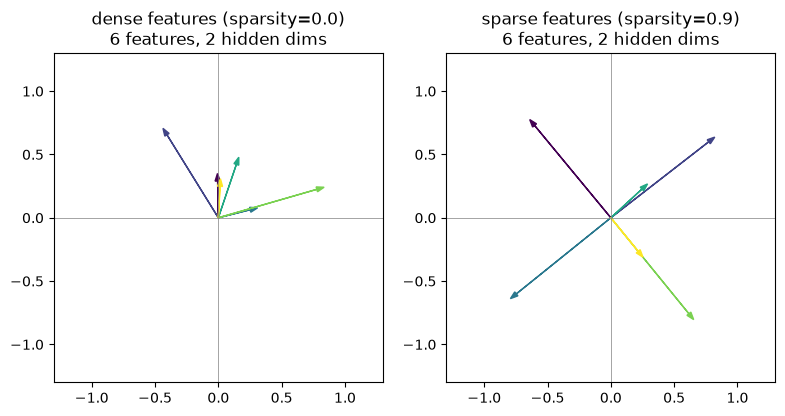

In [2]:
def plot_features(ax, model, title):
    W = model.W.detach()  # (2, n_features): each column is one feature's direction in hidden space
    colors = plt.cm.viridis(torch.linspace(0, 1, N_FEATURES))
    for i in range(N_FEATURES):
        ax.arrow(0, 0, W[0, i].item(), W[1, i].item(), head_width=0.04,
                  length_includes_head=True, color=colors[i])
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.set_aspect("equal")
    ax.axhline(0, color="gray", lw=0.5)
    ax.axvline(0, color="gray", lw=0.5)
    ax.set_title(title)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
plot_features(axes[0], dense_model, "dense features (sparsity=0.0)\n6 features, 2 hidden dims")
plot_features(axes[1], sparse_model, "sparse features (sparsity=0.9)\n6 features, 2 hidden dims")
plt.tight_layout()
plt.show()


Each arrow is one feature's learned direction in the model's 2D hidden space; length is roughly "how
well-represented" that feature is. With **dense** features (left), the model can't afford to spread all 6
out: overlapping directions would constantly interfere with each other, so it shrinks several features
down rather than represent them cleanly. With **sparse** features (right), the same 6 features spread out
further and land closer to unit length: because they rarely co-occur, the interference from being
non-orthogonal almost never actually matters, so the model "risks" packing more features into the same 2
dimensions. That's superposition: not a bug, a genuine compression strategy the model adopts when it pays
off.

This is exactly the setting real transformers are in, at a vastly larger scale: far more potential features
than residual-stream dimensions, and most features (most of the time) are sparse. An SAE with a wide
dictionary is the tool for *undoing* this compression after the fact, unpacking a `d_model`-width vector
back into the larger, sparser space where each feature gets its own dimension again. That's the SAE we
build next.


## Setup

This repeats the same handful of lines from `00_environment_and_activations.ipynb` (load the model,
grab a batch of residual-stream activations) so this notebook stands on its own. If you've already been
through notebook 00, this will feel familiar.


In [3]:
import torch
from transformer_lens import HookedTransformer

torch.manual_seed(0)
model = HookedTransformer.from_pretrained("gpt2", device="cpu")
LAYER = 6

# a small, varied set of short prompts, plenty for a toy demo, not for a real result
PROMPTS = [
    "The capital of France is Paris.",
    "The capital of Germany is Berlin.",
    "Two plus two equals four.",
    "Three plus three equals six.",
    "The sky is blue on a clear day.",
    "The ocean is deep and blue.",
    "The cat sat on the warm mat.",
    "The dog slept on the soft rug.",
    "Water boils at one hundred degrees.",
    "Ice melts at zero degrees.",
    "The sun rises in the east.",
    "The moon orbits the Earth.",
    "She opened the old wooden door.",
    "He closed the heavy metal gate.",
    "The train arrived at the station.",
    "The plane landed on the runway.",
    "Paris is the capital of France.",
    "Berlin is the capital of Germany.",
    "Five minus two equals three.",
    "Ten divided by two equals five.",
]

activations = []
with torch.no_grad():
    for p in PROMPTS:
        _, cache = model.run_with_cache(model.to_tokens(p))
        resid = cache[f"blocks.{LAYER}.hook_resid_post"][0]  # (position, d_model)
        activations.append(resid[1:])  # drop position 0, the prepended BOS token (an outlier "attention sink")

X = torch.cat(activations, dim=0)  # (total_tokens, d_model)
print(f"activation matrix X: {tuple(X.shape)}  (total_tokens, d_model)")


/tmp/ipykernel_3402/3855573954.py:5: DeprecationWarning: HookedTransformer.from_pretrained is deprecated and will be removed in a future major release. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics. See docs/source/content/migrating_to_v3.md.
  model = HookedTransformer.from_pretrained("gpt2", device="cpu")


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loaded pretrained model gpt2 into HookedTransformer


activation matrix X: (140, 768)  (total_tokens, d_model)


## A minimal SAE

- **Encoder**: `f = ReLU(W_enc @ x + b_enc)`, maps a `d_model`-dim activation to a `dict_size`-dim
  (much larger) sparse feature vector.
- **Decoder**: `x_hat = W_dec @ f + b_dec`, reconstructs the original activation from the sparse
  features.
- **Loss**: reconstruction error (`x` vs `x_hat`) plus an L1 penalty on `f` that pushes most features to
  exactly zero: this is what makes it *sparse*, not just an autoencoder.


In [4]:
import torch.nn as nn

class ToySAE(nn.Module):
    def __init__(self, d_model, dict_size):
        super().__init__()
        self.W_enc = nn.Parameter(torch.randn(d_model, dict_size) * 0.01)
        self.b_enc = nn.Parameter(torch.zeros(dict_size))
        self.W_dec = nn.Parameter(torch.randn(dict_size, d_model) * 0.01)
        self.b_dec = nn.Parameter(torch.zeros(d_model))

    def encode(self, x):
        return torch.relu((x - self.b_dec) @ self.W_enc + self.b_enc)

    def decode(self, f):
        return f @ self.W_dec + self.b_dec

    def forward(self, x):
        f = self.encode(x)
        x_hat = self.decode(f)
        return x_hat, f


In [5]:
def train_toy_sae(X, dict_size, l1_coeff=1e-3, epochs=300, lr=1e-3):
    sae = ToySAE(d_model=X.shape[1], dict_size=dict_size)
    opt = torch.optim.Adam(sae.parameters(), lr=lr)

    recon_losses, l0_history = [], []
    for _ in range(epochs):
        opt.zero_grad()
        x_hat, f = sae(X)
        recon_loss = ((x_hat - X) ** 2).mean()
        l1_loss = f.abs().mean()
        loss = recon_loss + l1_coeff * l1_loss
        loss.backward()
        opt.step()

        recon_losses.append(recon_loss.item())
        with torch.no_grad():
            l0_history.append((f > 1e-6).float().sum(dim=-1).mean().item())

    return sae, recon_losses, l0_history


## Train two dictionary sizes and compare

`PROPOSAL.md` § 4.2 treats dictionary size as "a deliberate experimental parameter" rather than
something to tune once and forget, because of the feature-splitting phenomenon Bricken et al. (2023)
document: a bigger dictionary can split one broad feature into several narrower ones. We won't see
anything as clean as real feature splitting on this toy dataset, but we *will* see the basic tradeoff:
a bigger dictionary can lower reconstruction loss, but at the cost of more active features per token
(higher L0), which is a real interpretability cost, not just a compute cost.


In [6]:
results = {}
for dict_size in [64, 256]:
    sae, recon_losses, l0_history = train_toy_sae(X, dict_size=dict_size)
    results[dict_size] = (sae, recon_losses, l0_history)
    print(f"dict_size={dict_size:>4}  final recon loss={recon_losses[-1]:.4f}  final avg L0={l0_history[-1]:.1f}")


dict_size=  64  final recon loss=0.5161  final avg L0=50.4


dict_size= 256  final recon loss=0.0399  final avg L0=168.3


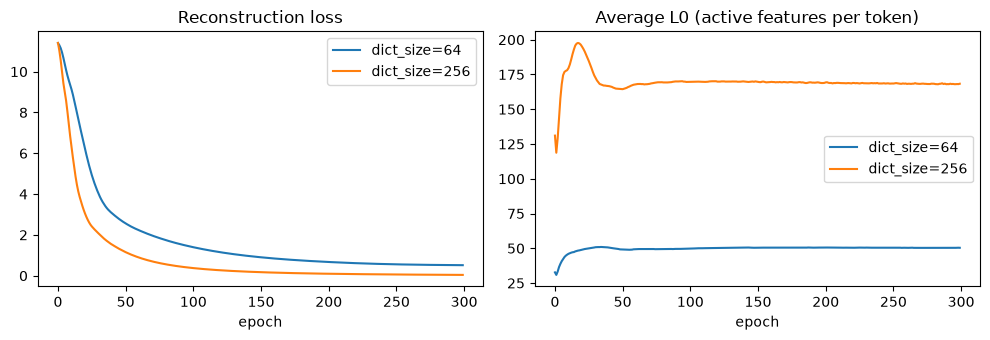

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for dict_size, (_, recon_losses, l0_history) in results.items():
    axes[0].plot(recon_losses, label=f"dict_size={dict_size}")
    axes[1].plot(l0_history, label=f"dict_size={dict_size}")

axes[0].set_title("Reconstruction loss")
axes[0].set_xlabel("epoch")
axes[1].set_title("Average L0 (active features per token)")
axes[1].set_xlabel("epoch")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()


## What you should take away

- An SAE is just an autoencoder with an L1 penalty pushing its hidden layer toward sparsity, nothing
  more exotic than that at its core.
- Reconstruction loss and sparsity (L0) trade off against each other, and dictionary size is one of the
  knobs that shifts that tradeoff, which is why `PROPOSAL.md` treats it as a real experimental variable.
- This toy version skips everything SAELens handles for you at scale: proper initialization, resampling
  dead features, learning-rate schedules, and training on millions of tokens instead of twenty short
  sentences. Expect the real pipeline to look more like a SAELens config than this raw PyTorch class.
